# Evaluasi Model Data Science: Studi Kasus Truk ODOL

Tugas kelompok Sains Data Terapan (SVPL261506), materi DS 11 Evaluasi Model.

**Tema:** pengawasan truk *Over Dimension Over Load* (ODOL), yaitu truk yang dimensi atau muatannya melebihi batas izin.
Keempat jenis evaluasi memakai tema yang sama:

| Bagian | Kasus | Data |
|---|---|---|
| 1. Regresi | Sensor *Weigh-in-Motion* (WIM) memperkirakan berat kotor truk saat melaju, dibandingkan dengan jembatan timbang statis | 10 truk, karangan |
| 2. Clustering | Mengelompokkan truk berdasarkan rasio dimensi dan rasio muatan terhadap batas izin | 12 truk, karangan |
| 3. Klasifikasi | Model menentukan status truk: `normal`, `overload`, atau `overdimension` | 30 truk, karangan |
| 4. Deteksi objek | Model YOLO11n hasil tugas sebelumnya mendeteksi `roda`, `truk_normal`, `truk_odol` | 5 gambar test asli, prediksi asli |

Setiap metrik dihitung **manual** langkah demi langkah, lalu dicocokkan dengan library (`scikit-learn`, `ultralytics`).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

pd.set_option("display.precision", 4)
DATA = Path("data")
FIG = Path("figures")
FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "axes.grid": True, "grid.alpha": 0.3})

## 1. Evaluasi Regresi

**Kasus.** Sensor WIM di jalan arteri memperkirakan berat kotor truk (ton) tanpa truk harus berhenti.
Nilai aktual diambil dari jembatan timbang statis. Pertanyaannya: seberapa dekat perkiraan WIM dengan berat sebenarnya?

Error tiap truk: $e_i = y_i - \hat{y}_i$.

| Metrik | Rumus |
|---|---|
| MAE | $\frac{1}{n}\sum \lvert y_i-\hat y_i\rvert$ |
| MSE | $\frac{1}{n}\sum (y_i-\hat y_i)^2$ |
| RMSE | $\sqrt{\text{MSE}}$ |
| R² | $1-\frac{\sum (y_i-\hat y_i)^2}{\sum (y_i-\bar y)^2}$ |
| MAPE | $\frac{100\%}{n}\sum \left\lvert\frac{y_i-\hat y_i}{y_i}\right\rvert$ |
| MPE | $\frac{100\%}{n}\sum \frac{y_i-\hat y_i}{y_i}$ |
| RAE | $\frac{\sum \lvert y_i-\hat y_i\rvert}{\sum \lvert y_i-\bar y\rvert}$ |
| RSE | $\frac{\sum (y_i-\hat y_i)^2}{\sum (y_i-\bar y)^2}$ |

In [2]:
reg = pd.read_csv(DATA / "regresi_berat_truk.csv")
y, y_hat = reg["berat_aktual_ton"].to_numpy(), reg["berat_prediksi_ton"].to_numpy()
y_bar = y.mean()

tabel = reg.copy()
tabel["e = y - ŷ"] = y - y_hat
tabel["|e|"] = np.abs(y - y_hat)
tabel["e²"] = (y - y_hat) ** 2
tabel["|e|/y (%)"] = np.abs(y - y_hat) / y * 100
tabel["e/y (%)"] = (y - y_hat) / y * 100
tabel["|y - ȳ|"] = np.abs(y - y_bar)
tabel["(y - ȳ)²"] = (y - y_bar) ** 2
print(f"n = {len(y)}, rata-rata aktual ȳ = {y_bar:.2f} ton")
tabel.round(4)

n = 10, rata-rata aktual ȳ = 22.91 ton


,truk,berat_aktual_ton,berat_prediksi_ton,e = y - ŷ,|e|,e²,|e|/y (%),e/y (%),|y - ȳ|,(y - ȳ)²
0,T01,8.2,8.9,-0.7,0.7,0.49,8.5366,-8.5366,14.71,216.3841
1,T02,12.5,11.8,0.7,0.7,0.49,5.6000,5.6000,10.41,108.3681
2,T03,15.0,16.1,-1.1,1.1,1.21,7.3333,-7.3333,7.91,62.5681
3,T04,18.4,17.6,0.8,0.8,0.64,4.3478,4.3478,4.51,20.3401
4,T05,21.7,23.0,-1.3,1.3,1.69,5.9908,-5.9908,1.21,1.4641
5,T06,24.3,23.5,0.8,0.8,0.64,3.2922,3.2922,1.39,1.9321
6,T07,26.8,28.9,-2.1,2.1,4.41,7.8358,-7.8358,3.89,15.1321
7,T08,30.5,29.4,1.1,1.1,1.21,3.6066,3.6066,7.59,57.6081
8,T09,33.1,35.8,-2.7,2.7,7.29,8.1571,-8.1571,10.19,103.8361
9,T10,38.6,36.2,2.4,2.4,5.76,6.2176,6.2176,15.69,246.1761


In [3]:
n = len(y)
sum_abs, sum_sq = tabel["|e|"].sum(), tabel["e²"].sum()
sum_abs_mean, sum_sq_mean = tabel["|y - ȳ|"].sum(), tabel["(y - ȳ)²"].sum()

manual_reg = {
    "MAE (ton)": sum_abs / n,
    "MSE (ton²)": sum_sq / n,
    "RMSE (ton)": np.sqrt(sum_sq / n),
    "R²": 1 - sum_sq / sum_sq_mean,
    "MAPE (%)": tabel["|e|/y (%)"].mean(),
    "MPE (%)": tabel["e/y (%)"].mean(),
    "RAE": sum_abs / sum_abs_mean,
    "RSE": sum_sq / sum_sq_mean,
}
print(f"Σ|e| = {sum_abs:.2f}   Σe² = {sum_sq:.2f}   Σ|y-ȳ| = {sum_abs_mean:.2f}   Σ(y-ȳ)² = {sum_sq_mean:.4f}\n")
for k, v in manual_reg.items():
    print(f"{k:<11} = {v:.4f}")

Σ|e| = 13.70   Σe² = 23.83   Σ|y-ȳ| = 77.50   Σ(y-ȳ)² = 833.8090

MAE (ton)   = 1.3700
MSE (ton²)  = 2.3830
RMSE (ton)  = 1.5437
R²          = 0.9714
MAPE (%)    = 6.0918
MPE (%)     = -1.4789
RAE         = 0.1768
RSE         = 0.0286


Verifikasi dengan `scikit-learn` (MPE, RAE, dan RSE tidak tersedia di sklearn, jadi hanya MAE, MSE, RMSE, R², MAPE yang dicek):

In [4]:
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error, r2_score

lib_reg = {
    "MAE (ton)": mean_absolute_error(y, y_hat),
    "MSE (ton²)": mean_squared_error(y, y_hat),
    "RMSE (ton)": np.sqrt(mean_squared_error(y, y_hat)),
    "R²": r2_score(y, y_hat),
    "MAPE (%)": mean_absolute_percentage_error(y, y_hat) * 100,
}
cek = pd.DataFrame({"manual": {k: manual_reg[k] for k in lib_reg}, "sklearn": lib_reg})
cek["cocok"] = np.isclose(cek["manual"], cek["sklearn"])
assert cek["cocok"].all()
cek

,manual,sklearn,cocok
MAE (ton),1.3700,1.3700,True
MSE (ton²),2.3830,2.3830,True
RMSE (ton),1.5437,1.5437,True
R²,0.9714,0.9714,True
MAPE (%),6.0918,6.0918,True


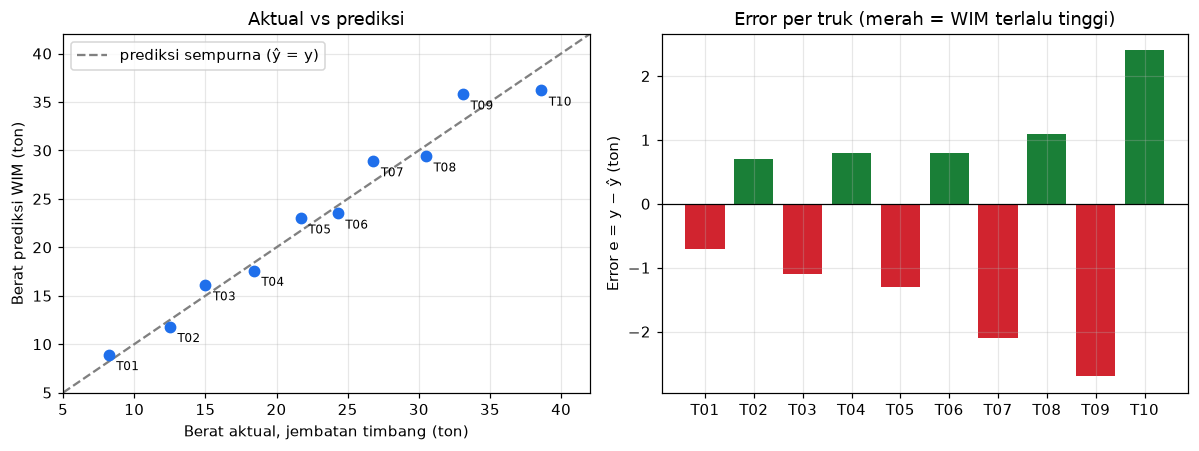

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ax = axes[0]
ax.scatter(y, y_hat, s=45, color="#1f6feb", zorder=3)
lim = [5, 42]
ax.plot(lim, lim, "--", color="gray", label="prediksi sempurna (ŷ = y)")
for t, a, p in zip(reg["truk"], y, y_hat):
    ax.annotate(t, (a, p), textcoords="offset points", xytext=(5, -10), fontsize=8)
ax.set(xlim=lim, ylim=lim, xlabel="Berat aktual, jembatan timbang (ton)", ylabel="Berat prediksi WIM (ton)",
       title="Aktual vs prediksi")
ax.legend(loc="upper left")

ax = axes[1]
warna = ["#d1242f" if e < 0 else "#1a7f37" for e in y - y_hat]
ax.bar(reg["truk"], y - y_hat, color=warna)
ax.axhline(0, color="black", lw=0.8)
ax.set(ylabel="Error e = y − ŷ (ton)", title="Error per truk (merah = WIM terlalu tinggi)")
fig.tight_layout()
fig.savefig(FIG / "regresi_aktual_vs_prediksi.png")
plt.show()

**Interpretasi.**
- **MAE = 1,37 ton**: rata-rata perkiraan WIM meleset sekitar 1,4 ton per truk. **MAPE ≈ 6,1 %** artinya meleset sekitar 6 % dari berat sebenarnya.
- **RMSE ≈ 1,54 ton** lebih besar dari MAE karena ada beberapa error besar (T09 meleset 2,7 ton, T10 2,4 ton) yang dihukum lebih berat oleh kuadrat.
- **R² ≈ 0,971**: WIM menjelaskan sekitar 97 % variasi berat truk, jadi urutan berat truk ditebak dengan sangat baik.
- **MPE ≈ −1,5 %** (negatif) menunjukkan WIM sedikit cenderung *melebihkan* berat. Untuk penindakan ODOL ini perlu diwaspadai: truk yang sebenarnya patuh bisa tercatat overload, sehingga WIM cocok sebagai penyaring awal sebelum truk ditimbang ulang secara statis.

## 2. Evaluasi Clustering

**Kasus.** Petugas ingin mengelompokkan truk tanpa label berdasarkan dua fitur:
- `rasio_dimensi_pct`: panjang/tinggi bak dibanding batas izin (100 % = tepat di batas),
- `rasio_muatan_pct`: berat muatan dibanding Jumlah Berat yang Diizinkan (JBI).

Kedua fitur sudah dalam satuan yang sama (persen), sehingga jarak Euclidean bisa dipakai langsung tanpa normalisasi.
Clustering tidak punya label aktual, jadi yang dievaluasi adalah kualitas kelompok itu sendiri.

Langkah:
1. K-Means manual dengan $k=3$.
2. Hitung **Inertia**, **Silhouette**, **Davies-Bouldin Index** secara manual.
3. Bandingkan dengan `scikit-learn`, lalu cek pilihan $k$.

In [6]:
clu = pd.read_csv(DATA / "clustering_truk.csv")
X = clu[["rasio_dimensi_pct", "rasio_muatan_pct"]].to_numpy(dtype=float)
clu

,truk,rasio_dimensi_pct,rasio_muatan_pct
0,C01,88,82
1,C02,92,90
2,C03,95,86
3,C04,90,95
4,C05,98,128
5,C06,94,135
6,C07,104,112
7,C08,97,140
8,C09,125,145
9,C10,132,160


### 2.1 K-Means manual ($k=3$)

Centroid awal dipilih dari tiga truk: C01, C05, C09. Tiap iterasi: (1) setiap truk masuk ke centroid terdekat, (2) centroid diperbarui menjadi rata-rata anggotanya. Berhenti saat anggota cluster tidak berubah.

In [7]:
def jarak(a, b):
    return np.sqrt(((a - b) ** 2).sum(axis=-1))

centroid = X[[0, 4, 8]].copy()
label_lama = None
for it in range(1, 20):
    D = np.stack([jarak(X, c) for c in centroid], axis=1)
    label = D.argmin(axis=1)
    print(f"Iterasi {it}: centroid = {np.round(centroid, 2).tolist()}")
    print("  anggota:", {k: clu['truk'][label == k].tolist() for k in range(3)})
    if label_lama is not None and (label == label_lama).all():
        print("  anggota tidak berubah -> konvergen")
        break
    label_lama = label
    centroid = np.array([X[label == k].mean(axis=0) for k in range(3)])

clu["cluster"] = label
pd.DataFrame(np.round(D, 3), columns=["jarak ke c0", "jarak ke c1", "jarak ke c2"]).assign(truk=clu["truk"], cluster=label)

Iterasi 1: centroid = [[88.0, 82.0], [98.0, 128.0], [125.0, 145.0]]
  anggota: {0: ['C01', 'C02', 'C03', 'C04'], 1: ['C05', 'C06', 'C07', 'C08'], 2: ['C09', 'C10', 'C11', 'C12']}
Iterasi 2: centroid = [[91.25, 88.25], [98.25, 128.75], [126.25, 148.25]]
  anggota: {0: ['C01', 'C02', 'C03', 'C04'], 1: ['C05', 'C06', 'C07', 'C08'], 2: ['C09', 'C10', 'C11', 'C12']}
  anggota tidak berubah -> konvergen


,jarak ke c0,jarak ke c1,jarak ke c2,truk,cluster
0,7.045,47.860,76.499,C01,0
1,1.904,39.251,67.573,C02,0
2,4.373,42.873,69.654,C03,0
3,6.865,34.744,64.418,C04,0
4,40.319,0.791,34.758,C05,1
5,46.831,7.558,34.866,C06,1
6,26.956,17.709,42.534,C07,1
7,52.068,11.319,30.391,C08,1
8,66.027,31.299,3.482,C09,2
9,82.514,45.996,13.081,C10,2


### 2.2 Inertia

$$\text{Inertia} = \sum_{i=1}^{n} \lVert x_i - c_{k(i)} \rVert^2$$

Jumlah kuadrat jarak setiap truk ke centroid cluster-nya. Makin kecil, makin rapat.

In [8]:
clu["jarak² ke centroid"] = jarak(X, centroid[label]) ** 2
inertia_manual = clu["jarak² ke centroid"].sum()
print("Centroid akhir:")
for k, c in enumerate(centroid):
    print(f"  c{k} = ({c[0]:.2f}, {c[1]:.2f})")
print(f"\nInertia = {inertia_manual:.4f}")
clu.groupby("cluster")["jarak² ke centroid"].sum().rename("Σ jarak² per cluster")

Centroid akhir:
  c0 = (91.25, 88.25)
  c1 = (98.25, 128.75)
  c2 = (126.25, 148.25)

Inertia = 952.5000


cluster
0    119.5
1    499.5
2    333.5
Name: Σ jarak² per cluster, dtype: float64

### 2.3 Silhouette

Untuk tiap truk $i$:
- $a(i)$ = rata-rata jarak ke truk lain **di cluster yang sama** (kerapatan),
- $b(i)$ = rata-rata jarak ke truk di **cluster terdekat lainnya** (keterpisahan),
- $s(i) = \dfrac{b(i)-a(i)}{\max(a(i), b(i))}$, rentang −1 sampai +1.

Silhouette keseluruhan = rata-rata $s(i)$.

In [9]:
Dfull = jarak(X[:, None, :], X[None, :, :])
rows = []
for i in range(len(X)):
    sama = (label == label[i]) & (np.arange(len(X)) != i)
    a = Dfull[i, sama].mean()
    b_per = {k: Dfull[i, label == k].mean() for k in range(3) if k != label[i]}
    k_b = min(b_per, key=b_per.get)
    b = b_per[k_b]
    rows.append({"truk": clu["truk"][i], "cluster": label[i], "a(i)": a, "b(i)": b,
                 "cluster terdekat": k_b, "s(i)": (b - a) / max(a, b)})
sil = pd.DataFrame(rows)
sil_manual = sil["s(i)"].mean()
print(f"Silhouette rata-rata = {sil_manual:.4f}")
print(sil.groupby("cluster")["s(i)"].mean().rename("silhouette per cluster").round(4).to_string())
sil.round(4)

Silhouette rata-rata = 0.6294
cluster
0    0.7945
1    0.4782
2    0.6155


,truk,cluster,a(i),b(i),cluster terdekat,s(i)
0,C01,0,10.0532,48.2768,1,0.7918
1,C02,0,6.4431,39.7061,1,0.8377
2,C03,0,7.7860,43.1670,1,0.8196
3,C04,0,9.6112,35.4298,1,0.7287
4,C05,1,12.3973,35.3330,2,0.6491
5,C06,1,12.9910,35.5520,2,0.6346
6,C07,1,23.6765,27.1491,0,0.1279
7,C08,1,15.5781,31.2246,2,0.5011
8,C09,2,10.4133,33.0093,1,0.6845
9,C10,2,18.1780,47.0144,1,0.6134


### 2.4 Davies-Bouldin Index (DBI)

1. Sebaran cluster $s_i$ = rata-rata jarak anggota ke centroid-nya.
2. Jarak antarcentroid $M_{ij} = \lVert c_i - c_j\rVert$.
3. $R_{ij} = \dfrac{s_i + s_j}{M_{ij}}$, lalu $D_i = \max_{j\ne i} R_{ij}$.
4. $\text{DBI} = \dfrac{1}{k}\sum_i D_i$. Makin kecil makin baik.

In [10]:
s = np.array([jarak(X[label == k], centroid[k]).mean() for k in range(3)])
M = jarak(centroid[:, None, :], centroid[None, :, :])
R = np.full((3, 3), np.nan)
for i in range(3):
    for j in range(3):
        if i != j:
            R[i, j] = (s[i] + s[j]) / M[i, j]
Dmax = np.nanmax(R, axis=1)
dbi_manual = Dmax.mean()

print("Sebaran s_i      :", np.round(s, 4))
print("Jarak centroid M :\n", np.round(M, 4))
print("Matriks R_ij     :\n", np.round(R, 4))
print("D_i = max R_ij   :", np.round(Dmax, 4))
print(f"\nDBI = {dbi_manual:.4f}")

Sebaran s_i      : [5.0466 9.3443 8.3631]
Jarak centroid M :
 [[ 0.     41.1005 69.4622]
 [41.1005  0.     34.1211]
 [69.4622 34.1211  0.    ]]
Matriks R_ij     :
 [[   nan 0.3501 0.193 ]
 [0.3501    nan 0.519 ]
 [0.193  0.519     nan]]
D_i = max R_ij   : [0.3501 0.519  0.519 ]

DBI = 0.4627


### 2.5 Verifikasi dengan `scikit-learn`

In [11]:
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score

km = KMeans(n_clusters=3, init=X[[0, 4, 8]], n_init=1).fit(X)
cek = pd.DataFrame({
    "manual": {"Inertia": inertia_manual, "Silhouette": sil_manual, "Davies-Bouldin": dbi_manual},
    "sklearn": {"Inertia": km.inertia_, "Silhouette": silhouette_score(X, km.labels_),
                "Davies-Bouldin": davies_bouldin_score(X, km.labels_)},
})
cek["cocok"] = np.isclose(cek["manual"], cek["sklearn"])
assert cek["cocok"].all() and (km.labels_ == label).all()
print(f"Calinski-Harabasz (pelengkap, sklearn) = {calinski_harabasz_score(X, label):.2f}  (makin besar makin baik)")
cek

Calinski-Harabasz (pelengkap, sklearn) = 48.37  (makin besar makin baik)


,manual,sklearn,cocok
Inertia,952.5000,952.5000,True
Silhouette,0.6294,0.6294,True
Davies-Bouldin,0.4627,0.4627,True


### 2.6 Apakah $k=3$ pilihan yang tepat?

,k,Inertia,Silhouette,Davies-Bouldin
0,2,2981.9429,0.5820,0.5108
1,3,952.5000,0.6294,0.4627
2,4,534.3333,0.5763,0.3063
3,5,306.1667,0.4934,0.2780
4,6,225.8333,0.4258,0.2631


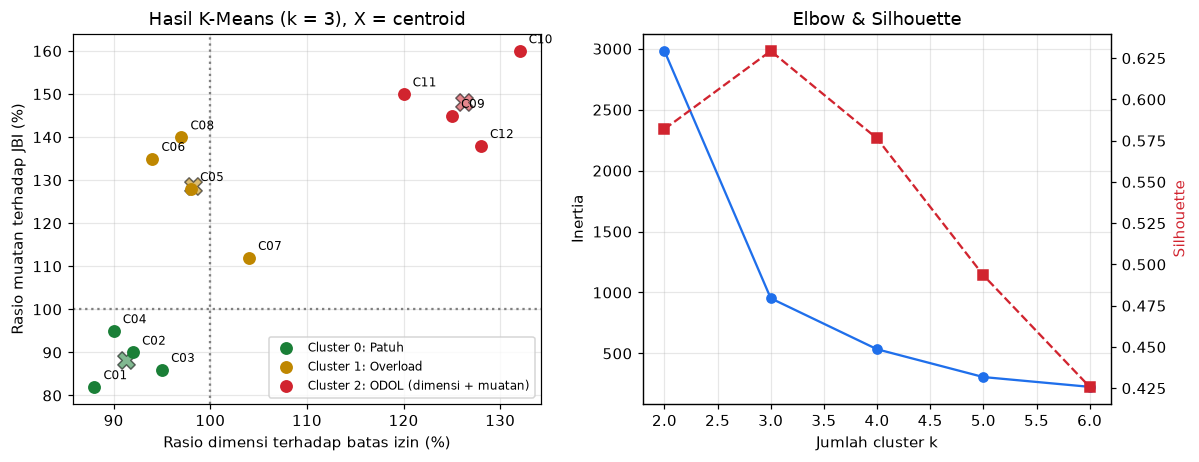

In [12]:
hasil_k = []
for k in range(2, 7):
    m = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X)
    hasil_k.append({"k": k, "Inertia": m.inertia_, "Silhouette": silhouette_score(X, m.labels_),
                    "Davies-Bouldin": davies_bouldin_score(X, m.labels_)})
hasil_k = pd.DataFrame(hasil_k)
display(hasil_k.round(4))

nama = {0: "Patuh", 1: "Overload", 2: "ODOL (dimensi + muatan)"}
warna = {0: "#1a7f37", 1: "#bf8700", 2: "#d1242f"}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
ax = axes[0]
for k in range(3):
    ax.scatter(*X[label == k].T, s=55, color=warna[k], label=f"Cluster {k}: {nama[k]}", zorder=3)
    ax.scatter(*centroid[k], marker="X", s=130, color=warna[k], edgecolor="black", alpha=0.55, zorder=2)
for t, (a, b) in zip(clu["truk"], X):
    ax.annotate(t, (a, b), textcoords="offset points", xytext=(6, 5), fontsize=8, zorder=5)
ax.axvline(100, ls=":", color="gray"); ax.axhline(100, ls=":", color="gray")
ax.set(xlabel="Rasio dimensi terhadap batas izin (%)", ylabel="Rasio muatan terhadap JBI (%)", title="Hasil K-Means (k = 3), X = centroid")
ax.legend(fontsize=8, loc="lower right")

ax = axes[1]
ax.plot(hasil_k["k"], hasil_k["Inertia"], "o-", color="#1f6feb")
ax.set(xlabel="Jumlah cluster k", ylabel="Inertia", title="Elbow & Silhouette")
ax2 = ax.twinx()
ax2.plot(hasil_k["k"], hasil_k["Silhouette"], "s--", color="#d1242f")
ax2.set_ylabel("Silhouette", color="#d1242f"); ax2.grid(False)
fig.tight_layout()
fig.savefig(FIG / "clustering_kmeans.png")
plt.show()

**Interpretasi.**
- **Silhouette ≈ 0,63**: cluster cukup kompak dan terpisah (di atas 0,5 umumnya dianggap struktur yang jelas). Truk **C07** punya $s(i)$ paling kecil karena posisinya di antara kelompok patuh dan overload (rasio muatan 112 %).
- **Davies-Bouldin ≈ 0,46**: kemiripan antarcluster rendah. Pasangan paling mirip adalah cluster overload dan ODOL ($R_{12} \approx 0{,}52$).
- **Inertia = 952,5**: sumbangan terbesar dari cluster overload (499,5) karena C07 jauh dari centroid-nya.
- **Pilihan k**: inertia turun tajam dari $k=2$ ke $k=3$ (2982 → 952) lalu melandai (siku), dan silhouette tertinggi juga di $k=3$. DBI memang terus turun saat $k$ bertambah, tetapi itu wajar karena cluster makin kecil; dengan dua metrik lain sepakat, $k=3$ dipilih.
- **Validasi bisnis**: ketiga cluster mudah dijelaskan: *patuh* (keduanya < 100 %), *overload* (muatan > JBI, dimensi wajar), dan *ODOL* (dimensi dan muatan sama-sama melebihi batas). Kelompok ODOL bisa diprioritaskan untuk penindakan dan normalisasi bak.

## 3. Evaluasi Klasifikasi (3 kelas)

**Kasus.** Model menentukan status pelanggaran utama tiap truk dari data sensor gerbang: `normal`, `overload` (muatan berlebih), atau `overdimension` (ukuran bak melebihi izin). Status aktual berasal dari pemeriksaan petugas. Ada 30 truk dengan komposisi tidak seimbang: 15 normal, 9 overload, 6 overdimension.

Untuk kasus multikelas, TP/FP/FN dihitung per kelas dengan cara *one-vs-rest*:
- **TP** = diagonal kelas tersebut,
- **FP** = jumlah kolom kelas itu dikurangi TP (diprediksi kelas itu padahal bukan),
- **FN** = jumlah baris kelas itu dikurangi TP (seharusnya kelas itu tapi terlewat),
- **TN** = sisanya.

In [13]:
kls = pd.read_csv(DATA / "klasifikasi_status_muatan.csv")
kls["hasil"] = np.where(kls["status_aktual"] == kls["status_prediksi"], "benar", "salah")
display(kls.head(10))
print("Jumlah per kelas aktual:", kls["status_aktual"].value_counts().to_dict())

,truk,status_aktual,status_prediksi,hasil
0,K01,overload,overload,benar
1,K02,normal,normal,benar
2,K03,normal,overload,salah
3,K04,normal,normal,benar
4,K05,overload,overload,benar
5,K06,normal,normal,benar
6,K07,overdimension,overdimension,benar
7,K08,normal,normal,benar
8,K09,overload,overload,benar
9,K10,normal,normal,benar


Jumlah per kelas aktual: {'normal': 15, 'overload': 9, 'overdimension': 6}


In [14]:
KELAS = ["normal", "overload", "overdimension"]
cm = pd.crosstab(pd.Categorical(kls["status_aktual"], KELAS), pd.Categorical(kls["status_prediksi"], KELAS),
                 rownames=["aktual"], colnames=["prediksi"])
cm_np = cm.to_numpy()
cm

prediksi,normal,overload,overdimension
aktual,,,
normal,13,2,0
overload,2,6,1
overdimension,1,1,4


In [15]:
total = cm_np.sum()
per_kelas = []
for i, k in enumerate(KELAS):
    TP = cm_np[i, i]
    FP = cm_np[:, i].sum() - TP
    FN = cm_np[i, :].sum() - TP
    TN = total - TP - FP - FN
    P = TP / (TP + FP)
    Rc = TP / (TP + FN)
    F1 = 2 * P * Rc / (P + Rc)
    per_kelas.append({"kelas": k, "TP": TP, "FP": FP, "FN": FN, "TN": TN, "support": TP + FN,
                      "precision": P, "recall": Rc, "F1": F1})
per_kelas = pd.DataFrame(per_kelas).set_index("kelas")

accuracy = np.trace(cm_np) / total
macro = per_kelas[["precision", "recall", "F1"]].mean()
weighted = per_kelas[["precision", "recall", "F1"]].mul(per_kelas["support"], axis=0).sum() / total

print(f"Accuracy = (13 + 6 + 4) / 30 = {accuracy:.4f}")
print(f"Macro avg    : P = {macro['precision']:.4f}, R = {macro['recall']:.4f}, F1 = {macro['F1']:.4f}")
print(f"Weighted avg : P = {weighted['precision']:.4f}, R = {weighted['recall']:.4f}, F1 = {weighted['F1']:.4f}")
per_kelas.round(4)

Accuracy = (13 + 6 + 4) / 30 = 0.7667
Macro avg    : P = 0.7597, R = 0.7333, F1 = 0.7442
Weighted avg : P = 0.7662, R = 0.7667, F1 = 0.7648


,TP,FP,FN,TN,support,precision,recall,F1
kelas,,,,,,,,
normal,13,3,2,12,15,0.8125,0.8667,0.8387
overload,6,3,3,18,9,0.6667,0.6667,0.6667
overdimension,4,1,2,23,6,0.8000,0.6667,0.7273


Verifikasi dengan `scikit-learn`:

In [16]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_recall_fscore_support

yt, yp = kls["status_aktual"], kls["status_prediksi"]
assert (confusion_matrix(yt, yp, labels=KELAS) == cm_np).all()
assert np.isclose(accuracy_score(yt, yp), accuracy)
p, r, f, _ = precision_recall_fscore_support(yt, yp, labels=KELAS)
assert np.allclose(p, per_kelas["precision"]) and np.allclose(r, per_kelas["recall"]) and np.allclose(f, per_kelas["F1"])
mp, mr, mf, _ = precision_recall_fscore_support(yt, yp, labels=KELAS, average="macro")
assert np.allclose([mp, mr, mf], macro)
print("Semua hasil manual cocok dengan sklearn.\n")
print(classification_report(yt, yp, labels=KELAS, digits=4))

Semua hasil manual cocok dengan sklearn.

               precision    recall  f1-score   support

       normal     0.8125    0.8667    0.8387        15
     overload     0.6667    0.6667    0.6667         9
overdimension     0.8000    0.6667    0.7273         6

     accuracy                         0.7667        30
    macro avg     0.7597    0.7333    0.7442        30
 weighted avg     0.7662    0.7667    0.7648        30



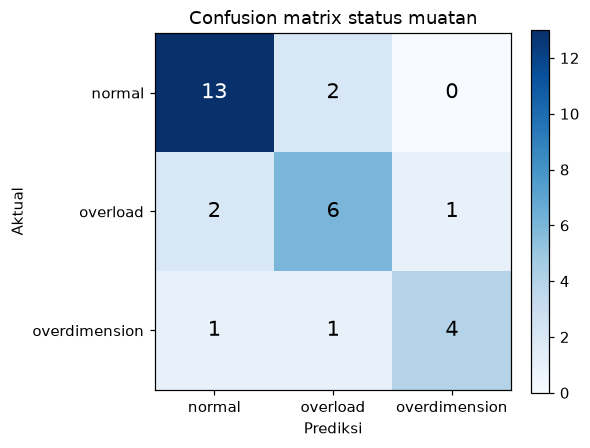

In [17]:
fig, ax = plt.subplots(figsize=(5.2, 4.4))
im = ax.imshow(cm_np, cmap="Blues")
ax.set_xticks(range(3), KELAS); ax.set_yticks(range(3), KELAS)
ax.set(xlabel="Prediksi", ylabel="Aktual", title="Confusion matrix status muatan")
ax.grid(False)
for i in range(3):
    for j in range(3):
        ax.text(j, i, cm_np[i, j], ha="center", va="center", fontsize=14,
                color="white" if cm_np[i, j] > cm_np.max() / 2 else "black")
fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()
fig.savefig(FIG / "klasifikasi_confusion_matrix.png")
plt.show()

**Interpretasi.**
- **Accuracy 76,7 %** terlihat lumayan, tetapi separuh data adalah truk `normal`. Model yang selalu menebak `normal` saja sudah dapat accuracy 50 %. Karena itu metrik per kelas dan **macro F1 ≈ 0,74** lebih jujur.
- Kelas `normal` paling baik (F1 ≈ 0,84). Kelas `overload` paling lemah presisinya (≈ 0,67): 3 dari 9 truk yang dituduh overload ternyata bukan.
- Kelas `overdimension` punya precision 0,80 tetapi **recall hanya 0,67**: 2 dari 6 truk overdimension lolos (1 dianggap normal, 1 dianggap overload). Untuk pengawasan ODOL, kesalahan ini paling berbahaya karena truk melanggar dibiarkan lewat, jadi recall kelas pelanggaran sebaiknya diprioritaskan.

## 4. Evaluasi Deteksi Objek

**Kasus.** Model YOLO11n dari tugas sebelumnya (`tugas/best.pt`) mendeteksi tiga kelas: `roda`, `truk_normal`, `truk_odol`.
Diambil 5 gambar dari *test set*: dua terdeteksi sempurna dan tiga yang mengandung kesalahan. Bounding box *ground truth* (GT) berasal dari anotasi Roboflow (format YOLO), prediksi berasal dari model dengan ambang confidence 0,25 (hasil `scripts/prediksi_deteksi.py`).

Langkah:
1. **IoU** = luas irisan / luas gabungan dua kotak.
2. **Pencocokan**: prediksi diurutkan dari confidence tertinggi. Prediksi = **TP** jika IoU ≥ 0,50 dengan GT **berkelas sama** yang belum dipakai; selain itu **FP**. GT yang tidak pernah cocok = **FN**.
3. **Precision** = TP / (TP + FP), **Recall** = TP / (TP + FN).
4. **AP** per kelas = luas di bawah kurva precision-recall. **mAP** = rata-rata AP semua kelas.

In [18]:
KELAS_DET = {0: "roda", 1: "truk_normal", 2: "truk_odol"}
DET = DATA / "deteksi"

gt_rows = []
for lbl in sorted((DET / "labels").glob("*.txt")):
    W, H = Image.open(DET / "images" / f"{lbl.stem}.jpg").size
    for j, line in enumerate(lbl.read_text().split("\n")):
        if not line.strip():
            continue
        c, xc, yc, w, h = map(float, line.split())
        gt_rows.append({"gambar": lbl.stem, "gt_id": f"G{len(gt_rows) + 1:02d}", "kelas": KELAS_DET[int(c)],
                        "x1": (xc - w / 2) * W, "y1": (yc - h / 2) * H, "x2": (xc + w / 2) * W, "y2": (yc + h / 2) * H})
gt = pd.DataFrame(gt_rows).round(1)
pred = pd.read_csv(DET / "prediksi_yolo.csv")
pred.insert(1, "pred_id", [f"P{i + 1:02d}" for i in range(len(pred))])
print(f"{len(gt)} kotak GT, {len(pred)} kotak prediksi")
display(gt)
pred

16 kotak GT, 18 kotak prediksi


,gambar,gt_id,kelas,x1,y1,x2,y2
0,truk_test_0001,G01,truk_odol,0.0,5.9,411.0,222.1
1,truk_test_0001,G02,roda,272.5,166.1,335.5,220.6
2,truk_test_0001,G03,roda,36.0,176.0,92.0,222.6
3,truk_test_0002,G04,truk_normal,0.5,5.5,389.5,211.5
4,truk_test_0002,G05,roda,256.0,151.8,320.0,206.6
5,truk_test_0002,G06,roda,47.0,157.8,105.0,206.6
6,truk_test_0010,G07,truk_odol,0.0,14.9,415.0,199.0
7,truk_test_0010,G08,roda,335.5,138.3,392.5,198.0
8,truk_test_0010,G09,roda,34.0,146.3,94.0,198.0
9,truk_test_0029,G10,truk_normal,1.5,2.5,406.5,178.5


,gambar,pred_id,kelas,confidence,x1,y1,x2,y2
0,truk_test_0001,P01,truk_odol,0.952,0.0,3.4,412.2,224.6
1,truk_test_0001,P02,roda,0.883,278.0,170.3,331.9,221.2
2,truk_test_0001,P03,roda,0.841,35.3,173.9,91.3,223.9
3,truk_test_0002,P04,truk_normal,0.924,0.0,2.4,391.2,212.9
4,truk_test_0002,P05,roda,0.809,43.9,155.4,102.4,210.8
5,truk_test_0002,P06,roda,0.683,258.4,153.4,314.3,210.5
6,truk_test_0010,P07,truk_odol,0.932,0.0,11.1,416.0,197.0
7,truk_test_0010,P08,roda,0.863,35.4,144.2,92.3,196.4
8,truk_test_0010,P09,roda,0.678,325.3,144.1,377.4,193.2
9,truk_test_0010,P10,roda,0.500,383.6,142.0,416.0,194.5


### 4.1 IoU

$$\text{IoU} = \frac{\lvert A \cap B\rvert}{\lvert A \cup B\rvert} = \frac{\text{irisan}}{\text{luas}_A + \text{luas}_B - \text{irisan}}$$

Contoh hitungan lengkap untuk satu pasangan, lalu matriks IoU tiap gambar.

In [19]:
def luas(b):
    return max(0.0, b[2] - b[0]) * max(0.0, b[3] - b[1])

def iou(a, b):
    irisan = luas([max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])])
    return irisan / (luas(a) + luas(b) - irisan)

BOX = ["x1", "y1", "x2", "y2"]
a = pred.loc[pred["pred_id"] == "P09", BOX].iloc[0].to_numpy()
b = gt.loc[gt["gt_id"] == "G08", BOX].iloc[0].to_numpy()
ix = [max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])]
print("Contoh: prediksi P09 (roda, gambar 0010) vs GT G08 (roda)")
print(f"  kotak prediksi = {a.tolist()}, luas = {luas(a):.1f}")
print(f"  kotak GT       = {b.tolist()}, luas = {luas(b):.1f}")
print(f"  irisan         = {np.round(ix, 1).tolist()}, luas = {luas(ix):.1f}")
print(f"  gabungan       = {luas(a):.1f} + {luas(b):.1f} - {luas(ix):.1f} = {luas(a) + luas(b) - luas(ix):.1f}")
print(f"  IoU            = {iou(a, b):.4f}  -> {'cocok' if iou(a, b) >= 0.5 else 'tidak cocok'} (ambang 0,50)")

Contoh: prediksi P09 (roda, gambar 0010) vs GT G08 (roda)
  kotak prediksi = [325.3, 144.1, 377.4, 193.2], luas = 2558.1
  kotak GT       = [335.5, 138.3, 392.5, 198.0], luas = 3402.9
  irisan         = [335.5, 144.1, 377.4, 193.2], luas = 2057.3
  gabungan       = 2558.1 + 3402.9 - 2057.3 = 3903.7
  IoU            = 0.5270  -> cocok (ambang 0,50)


In [20]:
for g in gt["gambar"].unique():
    P, G = pred[pred["gambar"] == g], gt[gt["gambar"] == g]
    mat = pd.DataFrame([[iou(p[BOX].to_numpy(), q[BOX].to_numpy()) for _, q in G.iterrows()] for _, p in P.iterrows()],
                       index=P["pred_id"] + " " + P["kelas"], columns=G["gt_id"] + " " + G["kelas"])
    print(f"\n{g}")
    display(mat.round(3))


truk_test_0001


,G01 truk_odol,G02 roda,G03 roda
P01 truk_odol,0.975,0.038,0.029
P02 roda,0.031,0.782,0.000
P03 roda,0.030,0.000,0.910



truk_test_0002


,G04 truk_normal,G05 roda,G06 roda
P04 truk_normal,0.973,0.043,0.034
P05 roda,0.040,0.000,0.803
P06 roda,0.040,0.798,0.000



truk_test_0010


,G07 truk_odol,G08 roda,G09 roda
P07 truk_odol,0.967,0.043,0.039
P08 roda,0.039,0.000,0.885
P09 roda,0.033,0.527,0.000
P10 roda,0.022,0.101,0.000



truk_test_0029


,G10 truk_normal,G11 roda,G12 roda
P11 truk_odol,0.962,0.043,0.041
P12 roda,0.046,0.000,0.886
P13 roda,0.046,0.935,0.000
P14 roda,0.028,0.000,0.000



truk_test_0100


,G13 truk_odol,G14 roda,G15 roda,G16 roda
P15 truk_normal,0.900,0.019,0.016,0.017
P16 roda,0.020,0.886,0.000,0.000
P17 roda,0.019,0.000,0.874,0.000
P18 roda,0.021,0.000,0.000,0.455


### 4.2 Pencocokan TP / FP / FN (IoU ≥ 0,50)

Kolom `IoU` hanya terhadap GT berkelas sama. Kolom `IoU maks (kelas apa pun)` membantu membedakan dua jenis FP: kotak tepat tetapi kelas salah, atau kotak yang memang meleset.

In [21]:
def cocokkan(pred, gt, ambang=0.5):
    hasil = pred.copy()
    hasil[["status", "gt_cocok", "IoU"]] = ["FP", "-", 0.0]
    terpakai = set()
    for idx in pred.sort_values("confidence", ascending=False).index:
        p = pred.loc[idx]
        kandidat = gt[(gt["gambar"] == p["gambar"]) & (gt["kelas"] == p["kelas"]) & ~gt["gt_id"].isin(terpakai)]
        if kandidat.empty:
            continue
        nilai = kandidat[BOX].apply(lambda q: iou(p[BOX].to_numpy(), q.to_numpy()), axis=1)
        best = nilai.idxmax()
        hasil.loc[idx, "IoU"] = nilai[best]
        if nilai[best] >= ambang:
            hasil.loc[idx, ["status", "gt_cocok"]] = ["TP", gt.loc[best, "gt_id"]]
            terpakai.add(gt.loc[best, "gt_id"])
    hasil["IoU maks (kelas apa pun)"] = [max(iou(p[BOX].to_numpy(), q[BOX].to_numpy()) for _, q in gt[gt["gambar"] == p["gambar"]].iterrows())
                                         for _, p in pred.iterrows()]
    fn = gt[~gt["gt_id"].isin(terpakai)]
    return hasil, fn

match, fn = cocokkan(pred, gt)
display(match[["gambar", "pred_id", "kelas", "confidence", "IoU", "IoU maks (kelas apa pun)", "status", "gt_cocok"]].round(3))
print("GT yang tidak terdeteksi (FN):")
fn[["gambar", "gt_id", "kelas"]]

,gambar,pred_id,kelas,confidence,IoU,IoU maks (kelas apa pun),status,gt_cocok
0,truk_test_0001,P01,truk_odol,0.952,0.975,0.975,TP,G01
1,truk_test_0001,P02,roda,0.883,0.782,0.782,TP,G02
2,truk_test_0001,P03,roda,0.841,0.910,0.910,TP,G03
3,truk_test_0002,P04,truk_normal,0.924,0.973,0.973,TP,G04
4,truk_test_0002,P05,roda,0.809,0.803,0.803,TP,G06
5,truk_test_0002,P06,roda,0.683,0.798,0.798,TP,G05
6,truk_test_0010,P07,truk_odol,0.932,0.967,0.967,TP,G07
7,truk_test_0010,P08,roda,0.863,0.885,0.885,TP,G09
8,truk_test_0010,P09,roda,0.678,0.527,0.527,TP,G08
9,truk_test_0010,P10,roda,0.500,0.000,0.101,FP,-


GT yang tidak terdeteksi (FN):


,gambar,gt_id,kelas
9,truk_test_0029,G10,truk_normal
12,truk_test_0100,G13,truk_odol
15,truk_test_0100,G16,roda


In [22]:
rekap = []
for k in KELAS_DET.values():
    TP = ((match["kelas"] == k) & (match["status"] == "TP")).sum()
    FP = ((match["kelas"] == k) & (match["status"] == "FP")).sum()
    FN = (fn["kelas"] == k).sum()
    rekap.append({"kelas": k, "GT": TP + FN, "prediksi": TP + FP, "TP": TP, "FP": FP, "FN": FN,
                  "precision": TP / (TP + FP), "recall": TP / (TP + FN)})
rekap = pd.DataFrame(rekap).set_index("kelas")
semua = rekap[["GT", "prediksi", "TP", "FP", "FN"]].sum()
rekap.loc["semua kelas"] = [*semua, semua["TP"] / (semua["TP"] + semua["FP"]), semua["TP"] / (semua["TP"] + semua["FN"])]
rekap.round(4)

,GT,prediksi,TP,FP,FN,precision,recall
kelas,,,,,,,
roda,11,13,10,3,1,0.7692,0.9091
truk_normal,2,2,1,1,1,0.5000,0.5000
truk_odol,3,3,2,1,1,0.6667,0.6667
semua kelas,16,18,13,5,3,0.7222,0.8125


### 4.3 Average Precision (AP) dan mAP

Untuk tiap kelas, prediksi diurutkan dari confidence tertinggi lalu dihitung precision dan recall kumulatif.
AP dihitung dengan interpolasi *all-point* (VOC 2010+): precision dibuat tidak naik dari kanan ke kiri ($p_{\text{interp}}(r) = \max_{\tilde r \ge r} p(\tilde r)$), lalu luas di bawah kurva dijumlahkan per segmen recall:

$$\text{AP} = \sum_n (r_{n} - r_{n-1})\, p_{\text{interp}}(r_n)$$

In [23]:
def kurva_pr(match, fn, kelas):
    m = match[match["kelas"] == kelas].sort_values("confidence", ascending=False).copy()
    n_gt = (m["status"] == "TP").sum() + (fn["kelas"] == kelas).sum()
    m["TP kum"] = (m["status"] == "TP").cumsum()
    m["FP kum"] = (m["status"] == "FP").cumsum()
    m["precision"] = m["TP kum"] / (m["TP kum"] + m["FP kum"])
    m["recall"] = m["TP kum"] / n_gt
    return m, n_gt

def ap_all_point(recall, precision):
    r = np.concatenate([[0.0], recall, [1.0]])
    p = np.concatenate([[1.0], precision, [0.0]])
    p = np.flip(np.maximum.accumulate(np.flip(p)))
    i = np.where(r[1:] != r[:-1])[0]
    return np.sum((r[i + 1] - r[i]) * p[i + 1])

ap = {}
for k in KELAS_DET.values():
    m, n_gt = kurva_pr(match, fn, k)
    ap[k] = ap_all_point(m["recall"].to_numpy(), m["precision"].to_numpy())
    print(f"\nKelas {k} (jumlah GT = {n_gt}) -> AP = {ap[k]:.4f}")
    display(m[["pred_id", "gambar", "confidence", "status", "TP kum", "FP kum", "precision", "recall"]].round(4))

map50 = np.mean(list(ap.values()))
print(f"mAP@0.50 = ({' + '.join(f'{v:.4f}' for v in ap.values())}) / 3 = {map50:.4f}")


Kelas roda (jumlah GT = 11) -> AP = 0.9091


,pred_id,gambar,confidence,status,TP kum,FP kum,precision,recall
1,P02,truk_test_0001,0.883,TP,1,0,1.0000,0.0909
7,P08,truk_test_0010,0.863,TP,2,0,1.0000,0.1818
15,P16,truk_test_0100,0.861,TP,3,0,1.0000,0.2727
16,P17,truk_test_0100,0.850,TP,4,0,1.0000,0.3636
2,P03,truk_test_0001,0.841,TP,5,0,1.0000,0.4545
11,P12,truk_test_0029,0.824,TP,6,0,1.0000,0.5455
4,P05,truk_test_0002,0.809,TP,7,0,1.0000,0.6364
5,P06,truk_test_0002,0.683,TP,8,0,1.0000,0.7273
8,P09,truk_test_0010,0.678,TP,9,0,1.0000,0.8182
12,P13,truk_test_0029,0.573,TP,10,0,1.0000,0.9091



Kelas truk_normal (jumlah GT = 2) -> AP = 0.5000


,pred_id,gambar,confidence,status,TP kum,FP kum,precision,recall
3,P04,truk_test_0002,0.924,TP,1,0,1.0,0.5
14,P15,truk_test_0100,0.910,FP,1,1,0.5,0.5



Kelas truk_odol (jumlah GT = 3) -> AP = 0.6667


,pred_id,gambar,confidence,status,TP kum,FP kum,precision,recall
0,P01,truk_test_0001,0.952,TP,1,0,1.0000,0.3333
6,P07,truk_test_0010,0.932,TP,2,0,1.0000,0.6667
10,P11,truk_test_0029,0.911,FP,2,1,0.6667,0.6667


mAP@0.50 = (0.9091 + 0.5000 + 0.6667) / 3 = 0.6919


**Verifikasi dengan `ultralytics`.** Fungsi `ap_per_class` milik ultralytics memakai interpolasi 101 titik (gaya COCO), jadi nilainya bisa sedikit berbeda dari all-point. mAP@0.50:0.95 (rata-rata mAP pada ambang IoU 0,50; 0,55; ...; 0,95) juga dihitung sebagai pelengkap.

In [24]:
from ultralytics.utils.metrics import ap_per_class

nama_ke_id = {v: k for k, v in KELAS_DET.items()}
ambang_iou = np.linspace(0.5, 0.95, 10)
tp_matrix = np.zeros((len(pred), len(ambang_iou)), dtype=bool)
map_manual_per_iou = []
for j, t in enumerate(ambang_iou):
    m_t, fn_t = cocokkan(pred, gt, ambang=t)
    tp_matrix[:, j] = (m_t["status"] == "TP").to_numpy()
    map_manual_per_iou.append(np.mean([ap_all_point(*[kurva_pr(m_t, fn_t, k)[0][c].to_numpy() for c in ("recall", "precision")])
                                       for k in KELAS_DET.values()]))

out = ap_per_class(tp_matrix, pred["confidence"].to_numpy(), pred["kelas"].map(nama_ke_id).to_numpy(),
                   gt["kelas"].map(nama_ke_id).to_numpy(), names=KELAS_DET)
ap_ul = out[5]  # shape (kelas, 10 ambang IoU)
banding = pd.DataFrame({"AP@0.50 manual (all-point)": ap, "AP@0.50 ultralytics (101 titik)": dict(zip(KELAS_DET.values(), ap_ul[:, 0]))})
banding.loc["mAP@0.50"] = banding.mean()
display(banding.round(4))
print(f"mAP@0.50:0.95  manual = {np.mean(map_manual_per_iou):.4f}   ultralytics = {ap_ul.mean():.4f}")
assert np.allclose(banding.iloc[:, 0], banding.iloc[:, 1], atol=0.02)

,AP@0.50 manual (all-point),AP@0.50 ultralytics (101 titik)
roda,0.9091,0.9050
truk_normal,0.5000,0.4950
truk_odol,0.6667,0.6650
mAP@0.50,0.6919,0.6883


mAP@0.50:0.95  manual = 0.5874   ultralytics = 0.5845


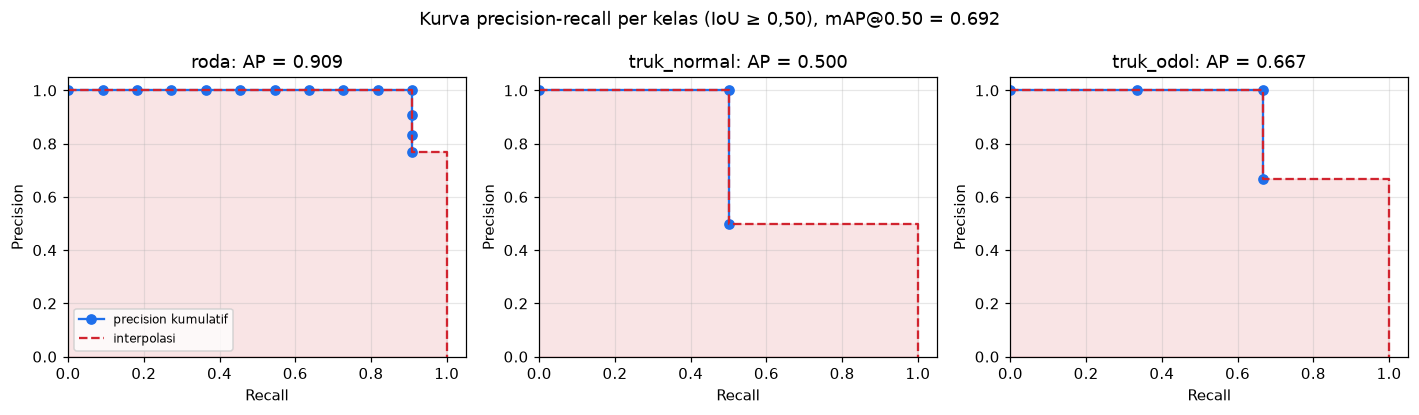

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, k in zip(axes, KELAS_DET.values()):
    m, _ = kurva_pr(match, fn, k)
    r = np.concatenate([[0], m["recall"]]); p = np.concatenate([[1], m["precision"]])
    ax.plot(r, p, "o-", color="#1f6feb", label="precision kumulatif")
    rr = np.concatenate([[0.0], m["recall"], [1.0]]); pp = np.flip(np.maximum.accumulate(np.flip(np.concatenate([[1.0], m["precision"], [0.0]]))))
    ax.step(rr, pp, where="post", color="#d1242f", ls="--", label="interpolasi")
    ax.fill_between(rr, pp, step="post", alpha=0.12, color="#d1242f")
    ax.set(xlim=(0, 1.05), ylim=(0, 1.05), xlabel="Recall", ylabel="Precision", title=f"{k}: AP = {ap[k]:.3f}")
axes[0].legend(fontsize=8, loc="lower left")
fig.suptitle(f"Kurva precision-recall per kelas (IoU ≥ 0,50), mAP@0.50 = {map50:.3f}")
fig.tight_layout()
fig.savefig(FIG / "deteksi_kurva_pr.png")
plt.show()

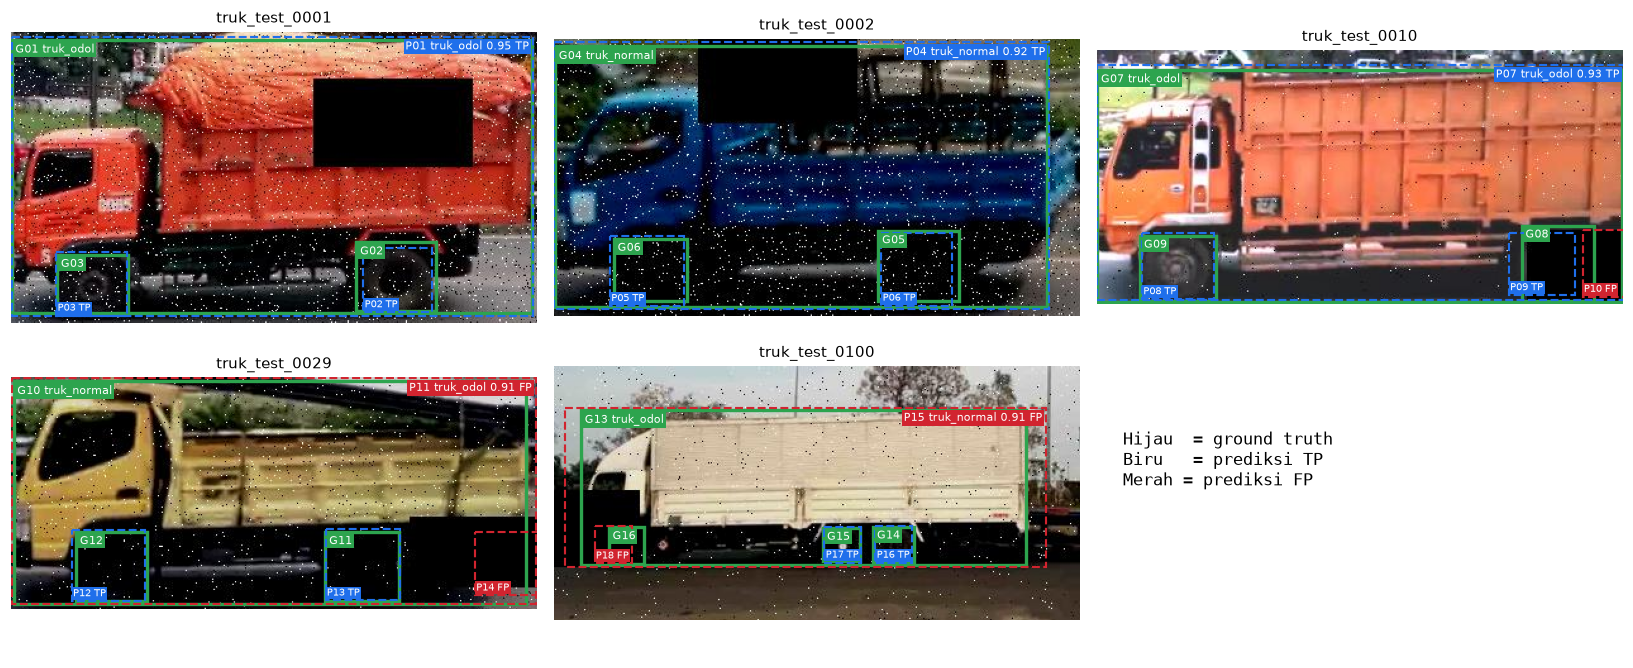

In [26]:
from PIL import ImageDraw

def gambar_hasil(nama, ax):
    im = Image.open(DET / "images" / f"{nama}.jpg").convert("RGB")
    ax.imshow(im); ax.axis("off"); ax.set_title(nama, fontsize=10)
    for _, g in gt[gt["gambar"] == nama].iterrows():
        ax.add_patch(plt.Rectangle((g.x1, g.y1), g.x2 - g.x1, g.y2 - g.y1, fill=False, ec="#2da44e", lw=2.2))
        besar = g.kelas != "roda"
        ax.text(g.x1 + 3, g.y1 + 3, f"{g.gt_id} {g.kelas}" if besar else g.gt_id, color="white", fontsize=7, va="top",
                bbox=dict(fc="#2da44e", ec="none", pad=1.2))
    for _, p in match[match["gambar"] == nama].iterrows():
        c = "#1f6feb" if p.status == "TP" else "#d1242f"
        ax.add_patch(plt.Rectangle((p.x1, p.y1), p.x2 - p.x1, p.y2 - p.y1, fill=False, ec=c, lw=1.4, ls="--"))
        if p.kelas == "roda":
            ax.text(p.x1 + 1, p.y2 - 2, f"{p.pred_id} {p.status}", color="white", fontsize=6.5, va="bottom",
                    bbox=dict(fc=c, ec="none", pad=1))
        else:
            ax.text(p.x2 - 3, p.y1 + 3, f"{p.pred_id} {p.kelas} {p.confidence:.2f} {p.status}", color="white", fontsize=7,
                    ha="right", va="top", bbox=dict(fc=c, ec="none", pad=1.2))

fig, axes = plt.subplots(2, 3, figsize=(15, 6.2))
for ax, nama in zip(axes.flat, gt["gambar"].unique()):
    gambar_hasil(nama, ax)
axes.flat[-1].axis("off")
axes.flat[-1].text(0.05, 0.6, "Hijau  = ground truth\nBiru   = prediksi TP\nMerah = prediksi FP", fontsize=11, family="monospace", va="center")
fig.tight_layout()
fig.savefig(FIG / "deteksi_gt_vs_prediksi.png")
plt.show()

**Interpretasi.**
- **Gambar 0001 dan 0002** terdeteksi sempurna: semua truk dan roda cocok dengan IoU tinggi.
- **Gambar 0029**: truk *normal* diprediksi sebagai `truk_odol` dengan confidence 0,91. Kotaknya tepat (IoU 0,96 terhadap GT), tetapi kelasnya salah, sehingga dihitung **1 FP** (`truk_odol`) sekaligus **1 FN** (`truk_normal`). Ada juga satu roda palsu (P14) di pojok kanan bawah yang tertutup bidang hitam.
- **Gambar 0100**: kebalikannya, truk ODOL diprediksi `truk_normal` (IoU 0,90, kelas salah). Roda paling kiri (P18) bergeser dari GT sehingga IoU hanya 0,455 < 0,50, jadi dihitung FP dan FN sekaligus walaupun objeknya sebenarnya ditemukan.
- **Gambar 0010**: roda kanan tertutup bidang hitam (noise augmentasi). Model membuat dua kotak: P09 cocok tipis (IoU 0,527, lolos ambang) dan P10 di sebelahnya menjadi FP. Kalau ambang IoU dinaikkan ke 0,55, P09 pun akan gagal.
- **AP `roda` = 0,91 paling tinggi**, karena ketiga FP-nya justru prediksi dengan confidence terendah (≤ 0,50), sehingga tidak menurunkan precision di bagian awal kurva. **mAP@0.50 = 0,69**, sedangkan kelas truk paling terdampak oleh tertukarnya `truk_normal` ↔ `truk_odol`. Untuk sistem penindakan ODOL, kebingungan kelas ini yang paling perlu diperbaiki, misalnya dengan menambah data truk normal yang mirip ODOL (bak tinggi, muatan penuh).

## 5. Ringkasan Hasil

In [27]:
ringkasan = pd.DataFrame([
    ["Regresi (WIM)", "MAE", f"{manual_reg['MAE (ton)']:.3f} ton"],
    ["Regresi (WIM)", "RMSE", f"{manual_reg['RMSE (ton)']:.3f} ton"],
    ["Regresi (WIM)", "R²", f"{manual_reg['R²']:.4f}"],
    ["Regresi (WIM)", "MAPE", f"{manual_reg['MAPE (%)']:.2f} %"],
    ["Clustering (k=3)", "Inertia", f"{inertia_manual:.2f}"],
    ["Clustering (k=3)", "Silhouette", f"{sil_manual:.4f}"],
    ["Clustering (k=3)", "Davies-Bouldin", f"{dbi_manual:.4f}"],
    ["Klasifikasi 3 kelas", "Accuracy", f"{accuracy:.4f}"],
    ["Klasifikasi 3 kelas", "Macro F1", f"{macro['F1']:.4f}"],
    ["Klasifikasi 3 kelas", "Weighted F1", f"{weighted['F1']:.4f}"],
    ["Deteksi objek (YOLO11n)", "Precision (semua kelas)", f"{rekap.loc['semua kelas', 'precision']:.4f}"],
    ["Deteksi objek (YOLO11n)", "Recall (semua kelas)", f"{rekap.loc['semua kelas', 'recall']:.4f}"],
    ["Deteksi objek (YOLO11n)", "mAP@0.50", f"{map50:.4f}"],
], columns=["Bagian", "Metrik", "Nilai"])
ringkasan.to_csv(FIG / "ringkasan_metrik.csv", index=False)
ringkasan

,Bagian,Metrik,Nilai
0,Regresi (WIM),MAE,1.370 ton
1,Regresi (WIM),RMSE,1.544 ton
2,Regresi (WIM),R²,0.9714
3,Regresi (WIM),MAPE,6.09 %
4,Clustering (k=3),Inertia,952.50
5,Clustering (k=3),Silhouette,0.6294
6,Clustering (k=3),Davies-Bouldin,0.4627
7,Klasifikasi 3 kelas,Accuracy,0.7667
8,Klasifikasi 3 kelas,Macro F1,0.7442
9,Klasifikasi 3 kelas,Weighted F1,0.7648
